# Take-Home Exercise 2: From Statistical Relationships to Decisions
## Assignment Details
**Module Title:** Data Analytics  
**CRN:** 23631  
**Student:** Rory Patrick Sheridan - A00082654  
**Submission File:** `A00082654_Rory_Sheridan_A2.pdf`  
**Dataset:**
Synthetic employee-level teaching dataset recording experience, training hours, post-programme investigation accuracy, and investigation times before and after a staff training programme, `A2_Employee_Performance.csv`.  
**Task:**
Analyse relationships, select and interpret inferential tests for paired observations, apply conditional probability and Bayes' theorem, compare decisions under uncertainty, and communicate defensible conclusions.

Github Repository:  
https://github.com/Ri-Dearg/da-labs  
Github Notebook:  
https://github.com/Ri-Dearg/da-labs/blob/main/lab2_employee_perf.ipynb

### Note
- This notebook is organised by assessment question. Each question section reports the analysis, the choices made and their justification. The findings are consolidated in the management brief in [Question 6](#question-6-evidence-based-management-recommendation) at the end.
- The dataset file supplied with the brief is stored unchanged in this repository as `emp_perf.csv`. The brief refers to it as both `A2_Employee_Performance.csv` and `AIML_H1003_A2_Employee_Performance.csv`.
- Questions 3, 4 and 5 a) use only the hypothetical parameters given in the brief, not the dataset.

## Summary
**Findings TBD**

## Table of Contents

<details>
<summary><a href="#tools--libraries">Tools & Libraries</a></summary>

- [Libraries](#libraries)

</details>

<details>
<summary><a href="#data-exploration">Data Exploration</a></summary>

- [Data Overview](#data-overview)
- [Data Quality Checks](#data-quality-checks)
- [Distributions](#distributions)
- [Data Treatment](#data-treatment)

</details>

<details>
<summary><a href="#question-1-understanding-relationships-between-variables">Question 1: Understanding Relationships between Variables</a></summary>

- [Go to section](#question-1-understanding-relationships-between-variables)

</details>

<details>
<summary><a href="#question-2-did-the-training-programme-improve-investigation-efficiency">Question 2: Did the Training Programme Improve Investigation Efficiency?</a></summary>

- [Go to section](#question-2-did-the-training-programme-improve-investigation-efficiency)

</details>

<details>
<summary><a href="#question-3-how-reliable-is-the-fraud-detection-system">Question 3: How Reliable Is the Fraud Detection System?</a></summary>

- [Go to section](#question-3-how-reliable-is-the-fraud-detection-system)

</details>

<details>
<summary><a href="#question-4-from-probability-to-decision-making">Question 4: From Probability to Decision-Making</a></summary>

- [Go to section](#question-4-from-probability-to-decision-making)

</details>

<details>
<summary><a href="#question-5-sensitivity-and-robustness">Question 5: Sensitivity and Robustness</a></summary>

- [Go to section](#question-5-sensitivity-and-robustness)

</details>

<details>
<summary><a href="#question-6-evidence-based-management-recommendation">Question 6: Evidence-Based Management Recommendation</a></summary>

- [Go to section](#question-6-evidence-based-management-recommendation)

</details>

<details>
<summary><a href="#references">References</a></summary>

- [AI Use Disclaimer](#ai-use-disclaimer)

</details>

## Tools & Libraries
1. [Matplotlib](https://matplotlib.org) - For plotting graphs.
2. [Pandas](https://pandas.pydata.org) - Dataframes and data manipulation
3. [Scipy](https://scipy.org) - For correlation coefficients and paired tests
4. [Seaborn](https://seaborn.pydata.org) - Plot library
5. [Jupyter](https://jupyter.org) - Notebook Tool

### Libraries
Libraries used.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import seaborn as sns

## Data Exploration

**Exploration summary**
- The dataset has 80 rows, one per employee, and 6 columns.
- There are no missing values or duplicated rows, and each `Employee_ID` appears only once.
- All values are within plausible ranges, so there is no clear sign of entry errors.

No rows were removed or changed.

### Data Overview

In [2]:
# Import data
df = pd.read_csv('emp_perf.csv')
df.head()

,Employee_ID,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
0,E001,12.1,15.5,80.7,40.1,32.7
1,E002,8.3,13.6,86.4,35.6,36.0
2,E003,17.4,20.7,83.8,38.9,22.2
3,E004,12.9,26.2,86.5,44.5,48.5
4,E005,12.1,28.3,88.5,47.8,45.4


In [3]:
# Show cols and rows
df.shape

(80, 6)

In [4]:
# View data stats
df.describe()

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
count,80.000000,80.000000,80.000000,80.000000,80.000000
mean,10.547500,20.482500,81.723750,42.318750,37.932500
std,5.414326,10.616345,6.427143,5.245808,7.716508
min,1.300000,3.300000,58.000000,28.000000,21.800000
25%,5.775000,11.475000,76.925000,38.900000,32.700000
50%,10.900000,19.800000,82.150000,42.000000,38.500000
75%,15.300000,28.700000,86.100000,45.975000,43.150000
max,19.400000,54.000000,93.800000,57.400000,60.800000


### Data Quality Checks
#### Types

In [5]:
# Explore structure of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_ID                 80 non-null     str    
 1   Experience_Years            80 non-null     float64
 2   Training_Hours              80 non-null     float64
 3   Investigation_Accuracy_pct  80 non-null     float64
 4   Time_Before_min             80 non-null     float64
 5   Time_After_min              80 non-null     float64
dtypes: float64(5), str(1)
memory usage: 3.9 KB


#### Duplicates

In [6]:
# Check for duplicates
df.duplicated().sum()

np.int64(0)

In [7]:
# Check that each employee appears only once
df['Employee_ID'].is_unique

True

#### Missing Values

In [8]:
# Check for missing values
df.isna().sum()

Employee_ID                   0
Experience_Years              0
Training_Hours                0
Investigation_Accuracy_pct    0
Time_Before_min               0
Time_After_min                0
dtype: int64

### Distributions

array([[<Axes: title={'center': 'Experience_Years'}>,
        <Axes: title={'center': 'Training_Hours'}>],
       [<Axes: title={'center': 'Investigation_Accuracy_pct'}>,
        <Axes: title={'center': 'Time_Before_min'}>],
       [<Axes: title={'center': 'Time_After_min'}>, <Axes: >]],
      dtype=object)

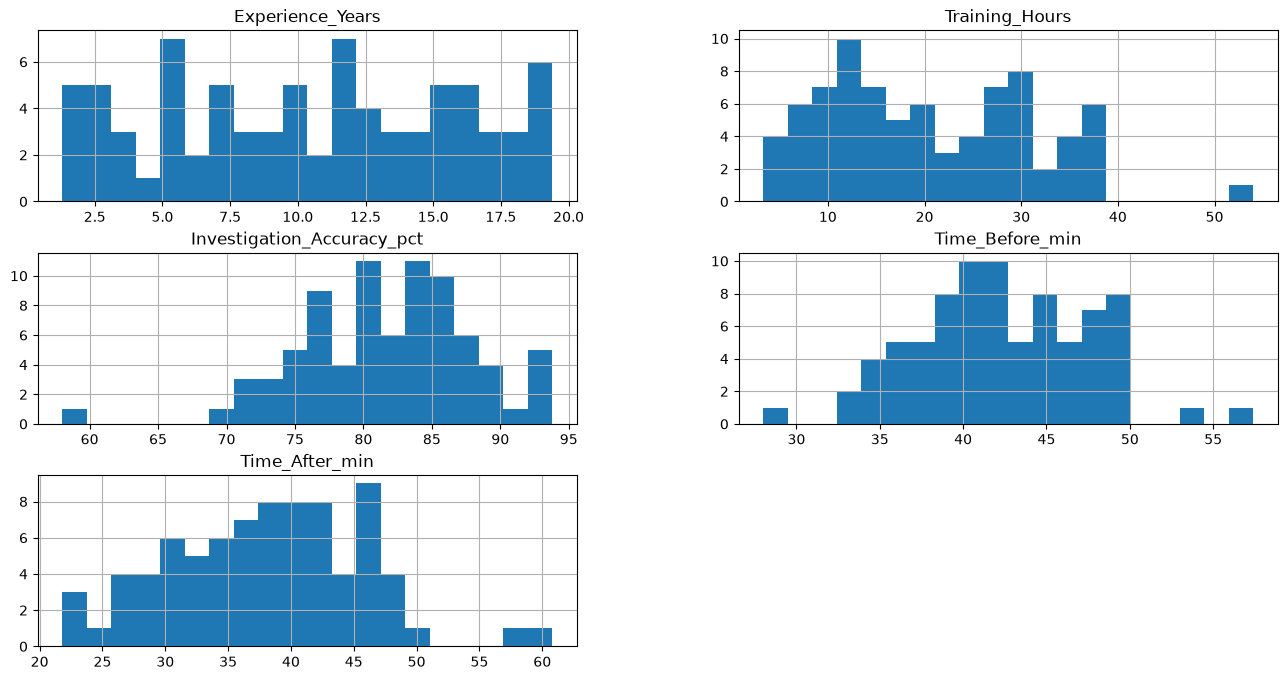

In [9]:
# Histograms for the distribution of each numeric variable
df.hist(figsize=(16, 8), bins=20)

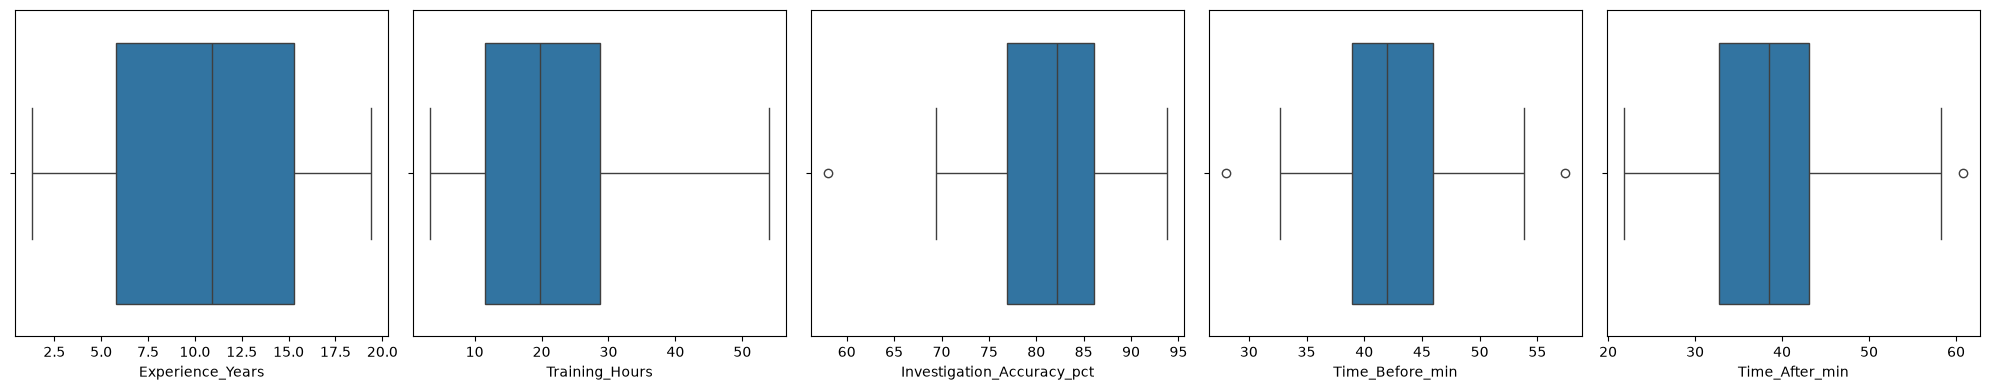

In [10]:
# Boxplots to check each numeric variable for outliers
cols = df.drop(columns='Employee_ID')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes.flat, cols, strict=True):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()

## Question 1: Understanding Relationships between Variables

### a) Calculate and interpret the sample covariance between training hours and investigation accuracy. Explain why covariance alone is insufficient for comparing the strength of relationships.

The sample covariance of Training Hours and Investigation Accuracy is 31.10. It is a positive number, they have a positive relationship, with the tendency that more training hours is associated with higher investigation accuracy. The sample covariance alone is not enough to tell us the strength of the relationship as the number is the two units multiplied together, hours by percentage points in this case. This value is not clearly interpretable and is not easily comparable with other values because it varies based on the units used to calculate it. This also means there's no indication whether the value is big or small, and no way to compare across variables. This is why correlation is often used to examine the relationship between variables.

In [20]:
df['Training_Hours'].cov(df['Investigation_Accuracy_pct'])

np.float64(31.095104430379752)

### b) Calculate the Pearson and Spearman correlation coefficients for training hours and investigation accuracy. Interpret their direction and strength.
n = 80  
Pearson correlation between the variables is 0.46.  
Spearman correlation between the variables is 0.66.  

These values indicate that the variables are positively correlated, with Pearson indicating moderate correlation and Spearman indicating a strong correlation. The higher spearman correlation indicates that the relationship between the two is not strictly linear, but may have a more complex relationship. Pearson is more sensitive to outliers, and the relationship may be monotonic but not linear, so it may underestimate the relationship.

In [18]:
df.corr(numeric_only=True, method='pearson')

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
Experience_Years,1.000000,-0.039728,0.326624,-0.308468,-0.331235
Training_Hours,-0.039728,1.000000,0.455721,0.106043,0.001693
Investigation_Accuracy_pct,0.326624,0.455721,1.000000,-0.215295,-0.308203
Time_Before_min,-0.308468,0.106043,-0.215295,1.000000,0.784264
Time_After_min,-0.331235,0.001693,-0.308203,0.784264,1.000000


In [19]:
df.corr(numeric_only=True, method='spearman')

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
Experience_Years,1.000000,-0.024100,0.300517,-0.349230,-0.359425
Training_Hours,-0.024100,1.000000,0.661779,0.123625,-0.010825
Investigation_Accuracy_pct,0.300517,0.661779,1.000000,-0.205130,-0.289387
Time_Before_min,-0.349230,0.123625,-0.205130,1.000000,0.761921
Time_After_min,-0.359425,-0.010825,-0.289387,0.761921,1.000000


### c) Produce a suitable scatterplot and assess whether the relationship appears linear, monotonic, or neither.
The relationship is roughly linear and monotonic. Overall, there is an upward trend, and the data points spread out, with a range of ~20% between them. One extreme outlier exists with a high amount of training hours and very low accuracy overall at 54 hours training, and 58% accuracy.  
  
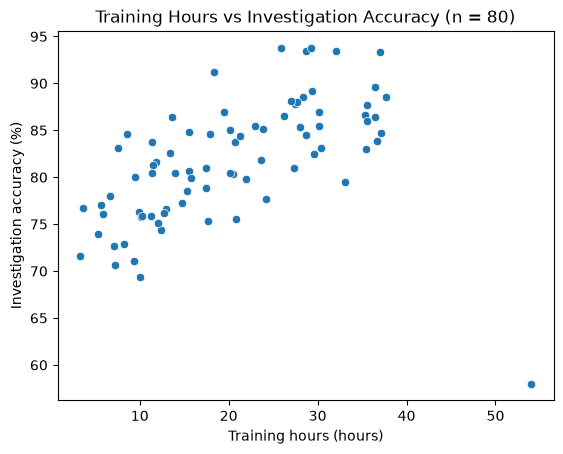

[Text(0.5, 0, 'Training hours (hours)'),
 Text(0, 0.5, 'Investigation accuracy (%)'),
 Text(0.5, 1.0, 'Training Hours vs Investigation Accuracy (n = 80)')]

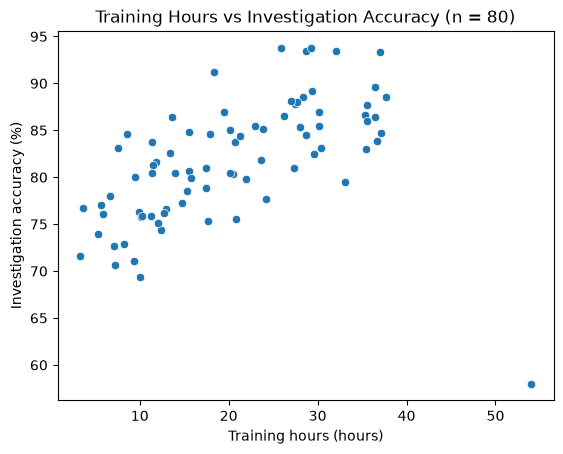

In [24]:
ax = sns.scatterplot(data=df, x='Training_Hours', y='Investigation_Accuracy_pct')
ax.set(
    xlabel='Training hours (hours)',
    ylabel='Investigation accuracy (%)',
    title='Training Hours vs Investigation Accuracy (n = 80)',
)

### d) Explain which correlation measure is more appropriate in this setting, taking account of outliers, measurement scales, and the observed relationship. Discuss whether the relationship establishes causation.

Spearman is the more appropriate correlation measure. This is due to the outlier being quite different from the other points, pulling Pearson down while Spearman's ranking is more robust to it. This factor impacts Pearson's capability to accurately measure correlation. The variables both use ratio measurements scales, so this does not impact Pearson. The relationship does not establish causation. Causation could lie with many other factors outside the range of this data, such as sleep hours, workload, case difficulty, etc. Correlation is clear, but causation is unproven.

## Question 2: Did the Training Programme Improve Investigation Efficiency?
The dataset (.csv file) includes investigation times for comparable tasks undertaken by the same employees before and after training. Define each paired difference as `Time_Before_min` − `Time_After_min`, so positive values indicate reduced investigation time.

### a) Define the paired differences, population of interest, null hypothesis, and alternative hypothesis. Explain why an independent-samples t-test would be inappropriate.

Each employee’s difference = Time_Before_min − Time_After_min, in minutes. Positive is faster, negative is slower.
The differences in time show that generally time improved by 4.39 minutes, but for certain employees decreased in performance, with a low of -7 minutes.  
The population of interest is all the investigators targeted for the training program.  

H0: μ_d = 0 The null hypothesis is that training did not change investigation efficiency.  
H1: μ_d ≠ 0 The alternative hypothesis is that training changed investigation efficiency, either positively or negatively.  

Independent t-samples aren't appropriate because the two features are dependent. The samples use the same 80 people so they're dependent. Using an independent t-test will have errors, inflating the variability and diminishing the effect.

In [26]:
df['Time_Diff_min'] = df['Time_Before_min'] - df['Time_After_min']
df['Time_Diff_min'].describe()

count    80.000000
mean      4.386250
std       4.854901
min      -7.000000
25%       0.500000
50%       5.050000
75%       7.100000
max      16.700000
Name: Time_Diff_min, dtype: float64

### b) Check whether a paired t-test is appropriate, using diagnostics for the distribution of within-employee differences and considering independence between employees. Explain limitations of the assumptions.

### c) Perform a paired t-test at the 5% significance level. Report the t-statistic, degrees of freedom, p-value, estimated mean paired difference, and its 95% confidence interval. Interpret the result in minutes. If assumptions are questionable, briefly describe a defensible alternative.

### d) Explain whether the findings demonstrate that training caused the observed change. Identify one plausible alternative explanation.

## Question 3: How Reliable Is the Fraud Detection System?
For this question, assume the following hypothetical system characteristics:

| Parameter | Value |
|:--|:--|
| Fraud prevalence | 2% |
| Sensitivity (true-positive rate) | 90% |
| Specificity (true-negative rate) | 95% |
| Transactions assessed | 10,000 |

### a) Define the events and calculate the probability that a randomly selected transaction is flagged.

### b) Use Bayes’ theorem to calculate the probability that a flagged transaction is fraudulent. Show your reasoning and calculations.

### c) Construct a confusion matrix of expected numbers of true positives, false positives, true negatives, and false negatives for 10,000 transactions.

### d) Explain how the system can have 90% sensitivity while a substantial proportion of its alerts are false positives.

## Question 4: From Probability to Decision-Making
Management must choose whether to investigate a flagged transaction. Assume the following hypothetical losses (monetary units per transaction):

| Decision | Fraudulent transaction | Legitimate transaction |
|:--|:--|:--|
| Investigate | 100 | 100 |
| Do not investigate | 2,000 | 0 |

### a) Using the posterior fraud probability from Question 3, calculate the expected loss of each decision for a flagged transaction.

### b) Recommend the decision that minimises expected loss. Explain why this may differ from a simple rule that investigates only if fraud is more likely than not.

### c) Derive the posterior probability threshold above which investigation has lower expected loss than not investigating.

### d) Identify one practical cost, impact, or constraint omitted from the simplified decision model.

## Question 5: Sensitivity and Robustness

### a) Recalculate the probability of fraud given a positive alert if fraud prevalence falls to 0.5%, while sensitivity and specificity remain unchanged. Compare your answer with Question 3 and explain the change.

### b) Identify and justify one potentially influential observation in the relationship analysed in Question 1. Recalculate Pearson and Spearman correlations excluding only that observation, compare them with the full-sample results, and discuss robustness. Report the observation ID and both sample sizes; retain it in the main analysis unless exclusion is defensible.

## Question 6: Evidence-Based Management Recommendation
Write a management brief of no more than 300 words that:
- a) states whether the employee programme appears effective, separating statistical evidence from causal claims;
- b) explains what the correlation findings establish and what remains uncertain;
- c) recommends whether flagged transactions should normally trigger investigations under the stated loss model;
- d) identifies one major limitation and one specific next analytical or operational action.

## References
**References TBD**

### AI Use Disclaimer
**Disclaimer TBD**: state the platform and model version, how it was used, the exact prompts, and what it produced (AI Driving Licence "Rules of the Road", principle 3).